In [28]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [29]:
%cd /content/drive/MyDrive/ColabNotebooks/IS110_bperformance_Gloria/ML_WORKBOOK/IS110_repo_Glory/ML_WORKBOOK

/content/drive/MyDrive/ColabNotebooks/IS110_bperformance_Gloria/ML_WORKBOOK/IS110_repo_Glory/ML_WORKBOOK


In [37]:
ls

'Colab Notebooks'/
'GLORIA - ML_Workbook_Wisconsin_Diagnostic.ipynb'
 WorkbookExercise_Gloria.ipynb
 world.py


In [36]:
!mv "/content/drive/MyDrive/Colab Notebooks/Colab Notebooks/WorkbookExercise_Gloria.ipynb" "/content/drive/MyDrive/Colab Notebooks"

In [38]:
!git config --global user.name 'Kyza Ann M. Gloria' #your full name
!git config --global user.email 'kyzaann.gloria@students.isatu.edu.ph' #the email address you used in creating your GitHub account
#!git config --global user.password = 'xxx your TOKEN xxx' #password should be the token
print('Done')

Done


In [39]:
!pwd

/content/drive/MyDrive/Colab Notebooks


# Applied Machine Learning Workbook: Breast Cancer Diagnosis
**Duration:** about 2 hours | **Level:** introductory | **Tools:** Python, pandas, scikit-learn, matplotlib

### How to use this workbook
- Run the cells in order. Cells containing `____` are **exercises**: replace each `____` with the correct code.
- Cells marked **Your turn** ask for your own code or a written answer.
- Everything runs offline. The dataset ships with scikit-learn, so nothing is downloaded.

### Learning objectives
1. Frame a supervised classification problem and choose a metric.
2. Profile a messy dataset with descriptive statistics and plots.
3. Clean data, select features and transform them **without data leakage**.
4. Spot-check several algorithms using cross-validation.
5. Improve a model with tuning and ensembles, then report an honest test score.

#### Name this file with your LASTNAME attached to it.
- Example: `WorkbookExercise_delaCruz.ipynb`
- Push this file to your github repo. Make sure to run everything before pushing to your repo.

# A. Problem Definition

## A.1 Brief Description
The Wisconsin Diagnostic Breast Cancer dataset contains 30 numeric measurements computed from digitized images of fine-needle aspirates of breast masses. The measurements describe the cell nuclei (radius, texture, perimeter, area, smoothness, and so on). Each of the 10 base properties is summarized three ways: **mean**, **standard error** and **worst** (largest value).

Each tumour is labelled **malignant (0)** or **benign (1)**.

> Teaching note: real data is rarely clean. To practise cleaning, the next cells deliberately inject missing values, impossible values and duplicate rows into the dataset (with a fixed random seed so everyone gets the same mess).

## A.2 Problem Statement
**Task:** predict whether a tumour is malignant or benign from its 30 measurements.

**Type:** supervised, binary classification.

**Primary metric:** accuracy. **Secondary metric:** recall for the malignant class (a missed malignant tumour is the costliest mistake).

**Your turn:** in one or two sentences, write who would use this model and what a false negative would cost them.

*Your answer:* A pathologist or clinician at a screening clinic would use this model as a second opinion when triaging fine-needle aspirate results. A false negative means a malignant tumour is labelled benign, so the patient’s diagnosis and treatment are delayed while the cancer may progress, which is far costlier than a false positive that only leads to extra tests.

## A.3 Load Packages

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             make_scorer, recall_score)

SEED = 42
np.random.seed(SEED)
print("Packages loaded.")

Packages loaded.


## A.4 Load Dataset

In [3]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()                 # column 'target': 0 = malignant, 1 = benign
feature_cols = list(data.feature_names)

# ---- Inject realistic mess (given; do not modify) ----
rng = np.random.default_rng(SEED)
mask = rng.random((len(df), len(feature_cols))) < 0.02            # ~2% missing cells
df[feature_cols] = df[feature_cols].mask(mask)
bad_idx = rng.choice(len(df), 3, replace=False)                   # 3 impossible values
df.loc[bad_idx, "mean area"] = -df.loc[bad_idx, "mean area"].abs()
df = pd.concat([df, df.sample(6, random_state=SEED)], ignore_index=True)   # 6 duplicate rows
# -------------------------------------------------------

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (575, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,NaN,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Your turn (check yourself):** how many rows and columns do you expect if the original dataset has 569 rows and 31 columns (30 features + target)? Does the output match, and why not?

# B. Summarize and Analyze Data

## B.1 Descriptive Statistics
Goal: understand size, types, balance, missingness and suspicious values *before* touching the data.

In [4]:
print("Column types:")
print(df.dtypes.value_counts(), "\n")

# Summary statistics for the first 8 features
df[feature_cols[:8]].describe().T

Column types:
float64    30
int64       1
Name: count, dtype: int64 



,count,mean,std,min,25%,50%,75%,max
mean radius,561.0,14.129339,3.546615,6.98100,11.680000,13.30000,15.850000,28.1100
mean texture,570.0,19.298211,4.315910,9.71000,16.172500,18.83500,21.795000,39.2800
mean perimeter,569.0,92.138330,24.409941,43.79000,75.170000,86.24000,104.700000,188.5000
mean area,569.0,647.726889,369.930801,-1479.00000,416.200000,546.40000,788.500000,2501.0000
mean smoothness,563.0,0.096598,0.014023,0.05263,0.086695,0.09639,0.105400,0.1634
mean compactness,565.0,0.104896,0.053317,0.01938,0.064920,0.09445,0.130500,0.3454
mean concavity,560.0,0.088927,0.080437,0.00000,0.029400,0.06188,0.127725,0.4268
mean concave points,562.0,0.049477,0.039034,0.00000,0.020682,0.03360,0.074660,0.2012


In [5]:
# Missing values, class balance, duplicates, impossible values
missing = df.isna().sum().sort_values(ascending=False)
print("Columns with most missing values:\n", missing.head(5), "\n")

print("Class balance (0 = malignant, 1 = benign):")
print(df["target"].value_counts(normalize=True).round(3), "\n")

print("Duplicate rows:", df.duplicated().sum())
print("Negative 'mean area' values:", (df["mean area"] < 0).sum())

skew = df[feature_cols].skew().sort_values(ascending=False)
print("\nMost right-skewed features:\n", skew.head(5))

Columns with most missing values:
 worst texture      17
worst perimeter    17
concavity error    17
worst radius       17
mean concavity     15
dtype: int64 

Class balance (0 = malignant, 1 = benign):
target
1    0.626
0    0.374
Name: proportion, dtype: float64 

Duplicate rows: 6
Negative 'mean area' values: 3

Most right-skewed features:
 area error                 5.447104
concavity error            5.174604
fractal dimension error    3.896955
perimeter error            3.415571
radius error               3.043449
dtype: float64


**Your turn:** answer in a markdown cell below.
1. Is the target balanced? Would plain accuracy be misleading here?

The target is moderately imbalanced: about 62.6% of rows are benign (1) and 37.4% are malignant (0). It isn’t severe, but a model that always predicted “benign” would already reach roughly 63% accuracy while catching zero malignant tumours. Accuracy alone can therefore flatter a weak model and hides the costliest mistake, a missed malignant case. That’s why recall for the malignant class (pos_label=0) should be reported next to accuracy, along with the confusion matrix.

2. Which features look most skewed, and what might that mean for algorithms like KNN or SVM?

The most right-skewed features are the standard-error (“error”) columns: area error (about 5.4), concavity error (about 5.2), fractal dimension error (about 3.9), perimeter error (about 3.4) and radius error (about 3.0). Their long right tails mean a few very large values pull the mean far above the median.

This matters for distance- and margin-based algorithms like KNN and SVM (RBF kernel). They compare raw numeric distances, so features with large scales or extreme outliers dominate the result. The scale gap is already visible in the table: mean area ranges up to about 2500, while mean smoothness stays below 0.2. Without scaling, area-type features would swamp the rest. The fix is to scale the features (e.g. StandardScaler, or RobustScaler if outliers are a concern), fitted on the training data only to avoid leakage. A log or PowerTransformer can further reduce the skew. Tree-based models (decision trees, random forests) don’t need this, because they split on thresholds and aren’t affected by scale or monotonic skew.


## B.2 Data Visualization
Three views: distributions (histograms), class separation (boxplots), and relationships (correlation heatmap).

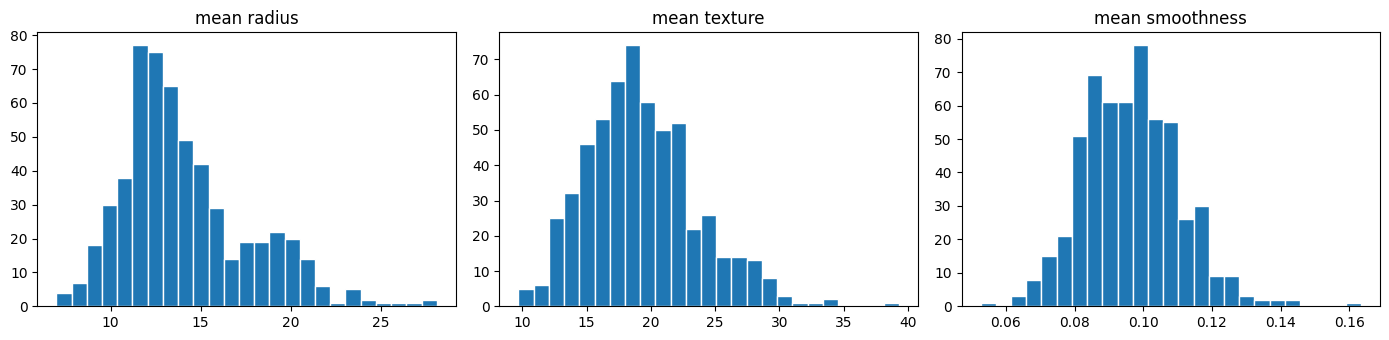

In [6]:
# Distributions
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["mean radius", "mean texture", "mean smoothness"]):
    ax.hist(df[col].dropna(), bins=25, edgecolor="white")
    ax.set_title(col)
plt.tight_layout()
plt.show()

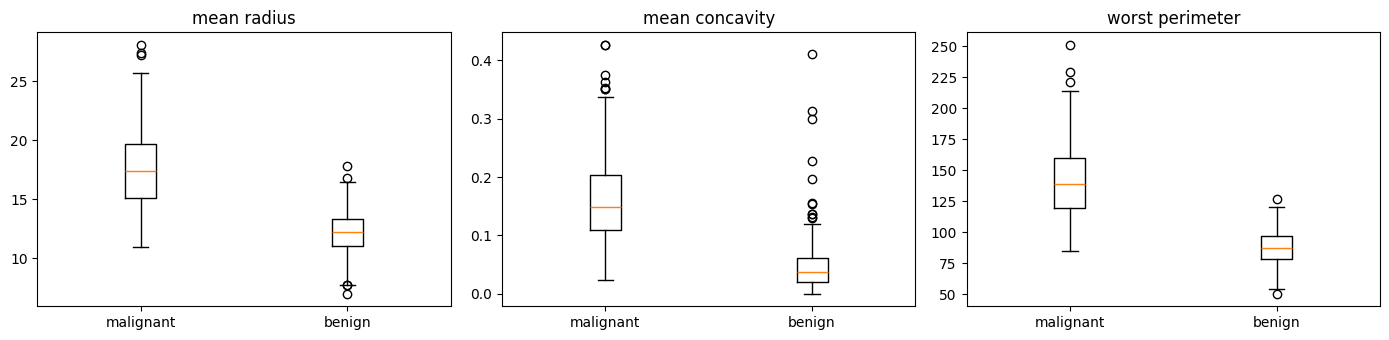

In [7]:
# Class separation: which features split malignant from benign?
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["mean radius", "mean concavity", "worst perimeter"]):
    groups = [df.loc[df["target"] == k, col].dropna() for k in (0, 1)]
    ax.boxplot(groups)
    ax.set_xticklabels(["malignant", "benign"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

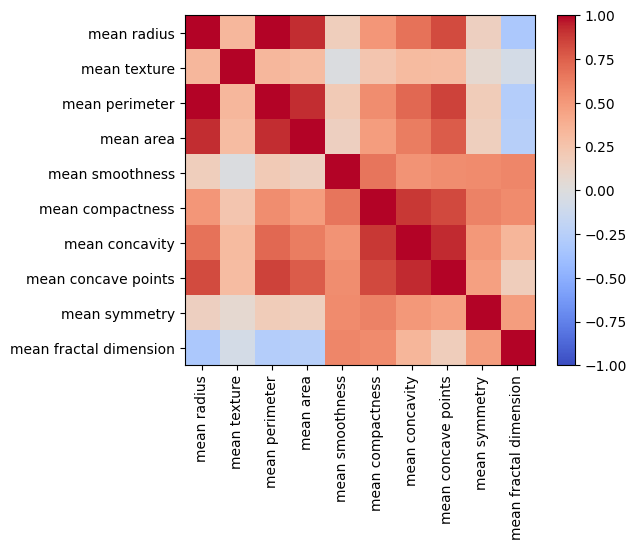

In [8]:
# Correlation heatmap of the 10 'mean' features
corr = df[feature_cols[:10]].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(10)); ax.set_xticklabels(feature_cols[:10], rotation=90)
ax.set_yticks(range(10)); ax.set_yticklabels(feature_cols[:10])
fig.colorbar(im)
plt.tight_layout()
plt.show()

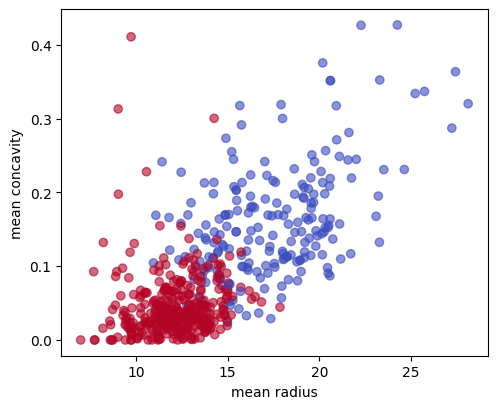

In [9]:
# Your turn: scatter plot of two features coloured by class
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(df["mean radius"], df["mean concavity"], c=df["target"], cmap="coolwarm", alpha=0.6)
ax.set_xlabel("mean radius"); ax.set_ylabel("mean concavity")
plt.show()

**Your turn:** which feature pairs are almost perfectly correlated (for example radius, perimeter and area)? Why does that matter for feature selection in Section C?

The size-related features are almost perfectly correlated. mean radius, mean perimeter and mean area all have correlations of about 0.98-1.0 with each other. This follows from geometry: perimeter is roughly 2πr and area is roughly πr², so all three measure nuclear size. The same holds for the “worst” versions (worst radius, worst perimeter, worst area). The “mean” and “worst” versions of the same property are also strongly correlated (e.g. mean radius and worst radius, about 0.97). Shape features are correlated too, though less strongly: mean concavity with mean concave points (about 0.9) and mean compactness with mean concavity (about 0.88).

This matters for feature selection because these features carry mostly the same information. Keeping all of them adds redundancy without adding signal, and the effects are:

Multicollinearity: in linear models like logistic regression, correlated features make coefficients unstable and hard to interpret.
Inflated importance: a feature that has many near-copies can look more important than it is.
Distorted distances: in KNN and SVM, a redundant group such as radius/perimeter/area effectively counts the “size” dimension several times.
No benefit, extra cost: more features means more computation and a higher risk of overfitting.

In Section C, I would drop one feature from each highly correlated pair (for example, remove features with correlation above about 0.95 to a feature already kept) or use a method that handles redundancy. The selection should be fitted on the training data only to avoid leakage.

# C. Prepare Data

> **Golden rule:** anything that *learns* from data (imputer means, scaler statistics, supervised feature selection) must be fitted on training data only. Otherwise information leaks from the test set and the final score is too optimistic.

## C.1 Data Cleaning
We do two safe fixes now (they use no statistics): remove duplicates and mark impossible values as missing. Missing-value *imputation* learns a statistic, so it goes inside a Pipeline later.

In [10]:
before = len(df)
df_clean = df.drop_duplicates().reset_index(drop=True)
print("Duplicates removed:", before - len(df_clean))

df_clean.loc[df_clean["mean area"] < 0, "mean area"] = np.nan

print("Rows with at least one missing value:", df_clean.isna().any(axis=1).sum(),
      f"({df_clean.isna().any(axis=1).mean():.1%})")
print("Rows left:", len(df_clean))

Duplicates removed: 6
Rows with at least one missing value: 255 (44.8%)
Rows left: 569


In [11]:
# Outlier check with the IQR rule (we only inspect; we do not delete)
q1, q3 = df_clean[feature_cols].quantile(0.25), df_clean[feature_cols].quantile(0.75)
iqr = q3 - q1
outliers = ((df_clean[feature_cols] < q1 - 1.5 * iqr) | (df_clean[feature_cols] > q3 + 1.5 * iqr)).sum()
print(outliers.sort_values(ascending=False).head(5))

area error          63
perimeter error     38
radius error        36
worst area          34
smoothness error    29
dtype: int64


**Your turn:** only ~2% of cells are missing, yet about 45% of rows have a gap. Why is *imputing* better than dropping those rows? Why is it risky to delete the flagged outliers here?

Why impute instead of drop? Each cell is only about 2% likely to be missing, but every row has 30 features, so the small per-cell rate compounds: the chance that a row has at least one gap is about 1 - 0.98³⁰, roughly 45%, which is what we observe (255 of 569 rows). Dropping those rows would discard almost half the data to lose only about 2% of the cells, leaving about 314 rows. With a small dataset that hurts the model and makes the test score noisier. It could also bias the sample if missingness isn’t completely random. Imputing keeps every row and its 29 or so valid measurements. The imputer (e.g. median) should sit inside the Pipeline so its statistic is learned from the training data only, with no leakage.

Why is deleting the flagged outliers risky? The IQR rule only says a value is unusual, not that it is wrong. In this dataset the extreme values are probably real: large tumours have genuinely large area, perimeter and radius, and the flagged columns (area error, perimeter error, radius error, worst area) are the skewed size features. Malignant tumours tend to be larger and more irregular, so the “outliers” are likely the malignant cases we most need to detect. Deleting them would remove exactly the cases that matter, shrink the malignant class further, and make the model look better on clean data than it will be on real patients. The better approach is to keep them and reduce their influence with a robust or transformed scaling (RobustScaler, log or PowerTransformer) or a model that isn’t sensitive to outliers. The one clearly invalid case, the negative areas, was already handled by converting it to missing.

Now split the data. The test set is locked away until Section E.

In [13]:
X = df_clean[feature_cols]
y = df_clean["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Malignant share train/test:", round((y_train == 0).mean(), 3), round((y_test == 0).mean(), 3))

Train: (455, 30)  Test: (114, 30)
Malignant share train/test: 0.374 0.368


## C.2 Feature Selection
Two ideas: (1) **filter redundant features** with very high pairwise correlation (unsupervised, so safe to do once on the training set), and (2) **rank features by relevance** to the target with an ANOVA F-test.

In [14]:
corr = X_train.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c] > 0.95).any()]
selected = [c for c in feature_cols if c not in to_drop]
print(f"Dropped {len(to_drop)} redundant features:", to_drop)
print(f"Kept {len(selected)} features.")

Dropped 7 redundant features: ['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']
Kept 23 features.


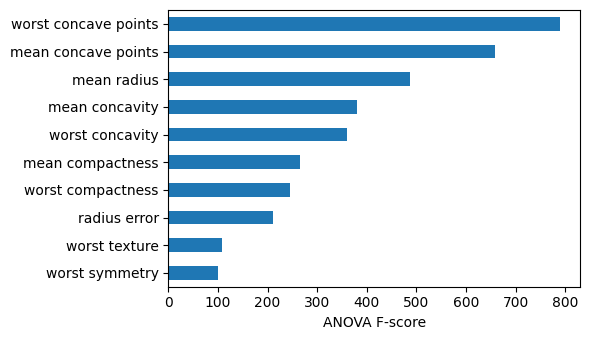

Top 5: ['worst concave points', 'mean concave points', 'mean radius', 'mean concavity', 'worst concavity']


In [15]:
# Rank remaining features by relevance (needs imputed data; fit on TRAIN only)
imp = SimpleImputer(strategy="median").fit(X_train[selected])
Xi = imp.transform(X_train[selected])

skb = SelectKBest(f_classif, k="all").fit(Xi, y_train)
scores = pd.Series(skb.scores_, index=selected).sort_values(ascending=False)

ax = scores.head(10).plot.barh(figsize=(6, 3.5))
ax.invert_yaxis(); ax.set_xlabel("ANOVA F-score")
plt.tight_layout(); plt.show()
print("Top 5:", [str(c) for c in scores.index[:5]])

**Your turn:** `SelectKBest` uses the target `y`. Explain in two sentences why it must live *inside* the cross-validation Pipeline (done in Section E) rather than being applied once to all the data.

SelectKBest uses the target y to decide which features to keep, so if it is fitted once on all the data, the labels of the future validation or test rows influence the feature choice, which is data leakage and makes the CV and test scores too optimistic. Inside a Pipeline, it is refit on only the training portion of each cross-validation fold, so every validation fold is scored on features chosen without ever seeing its labels, giving an honest estimate.

## C.3 Data Transform
Features live on very different scales (area is in the hundreds, smoothness below 0.2). Distance-based and margin-based models (KNN, SVM, logistic regression) are sensitive to this.

In [17]:
Xi_df = pd.DataFrame(Xi, columns=selected)
std_data = StandardScaler().fit_transform(Xi_df)
mm_data = MinMaxScaler().fit_transform(Xi_df)

print("Raw       feature std  : min %.3f  max %.1f" % (Xi_df.std().min(), Xi_df.std().max()))
print("Standard  feature std  : min %.3f  max %.3f" % (std_data.std(axis=0).min(), std_data.std(axis=0).max()))
print("MinMax    feature range: min %.1f  max %.1f" % (mm_data.min(), mm_data.max()))

Raw       feature std  : min 0.003  max 6.1
Standard  feature std  : min 1.000  max 1.000
MinMax    feature range: min 0.0  max 1.0


In [18]:
# Your turn: reduce skew with a log transform
before = Xi_df["concavity error"].skew()
after = np.log1p(Xi_df["concavity error"]).skew()
print(f"Skew of concavity error: {before:.2f} -> {after:.2f}")

Skew of concavity error: 5.28 -> 4.42


**Your turn:** which scaler would you pick if the data had many outliers, and why? (Hint: think about what a single extreme value does to min-max scaling.)

With many outliers I would pick RobustScaler. Min-max scaling uses the minimum and maximum, so a single extreme value stretches the range and squeezes all the normal values into a narrow band near 0 (or near 1), which destroys the useful spread between ordinary points. StandardScaler is also affected, because the mean and standard deviation are pulled by extreme values. RobustScaler subtracts the median and divides by the interquartile range (Q3 - Q1), and both of those statistics ignore the extremes, so outliers barely change how the typical values are scaled. The outliers stay as large values, but they no longer distort the scale for everyone else.

# D. Evaluate Algorithms

We **spot-check** five very different algorithms with identical conditions: 10-fold stratified cross-validation on the training set, inside a Pipeline (impute, scale, model) so nothing leaks.

In [19]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

def make_pipe(model, scale=True):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

models = {
    "LR":   LogisticRegression(max_iter=1000),
    "KNN":  KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=SEED),
    "NB":   GaussianNB(),
    "SVM":  SVC(),
}

results = {}
for name, model in models.items():
    s = cross_val_score(make_pipe(model), X_train[selected], y_train, cv=cv, scoring="accuracy")
    results[name] = s
    print(f"{name:5s} mean={s.mean():.4f}  std={s.std():.4f}")

LR    mean=0.9715  std=0.0170
KNN   mean=0.9583  std=0.0269
CART  mean=0.9341  std=0.0309
NB    mean=0.9167  std=0.0333
SVM   mean=0.9714  std=0.0141


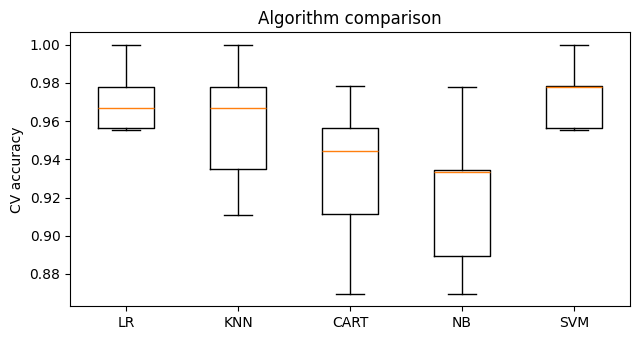

In [20]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.boxplot(list(results.values()))
ax.set_xticklabels(list(results.keys()))
ax.set_ylabel("CV accuracy"); ax.set_title("Algorithm comparison")
plt.tight_layout(); plt.show()

In [21]:
# Does scaling really matter? Re-run KNN and SVM without the scaler.
for name in ["KNN", "SVM"]:
    s = cross_val_score(make_pipe(models[name], scale=False), X_train[selected], y_train, cv=cv)
    print(f"{name:4s} without scaling: {s.mean():.4f}   (with scaling: {results[name].mean():.4f})")

KNN  without scaling: 0.9054   (with scaling: 0.9583)
SVM  without scaling: 0.8988   (with scaling: 0.9714)


In [22]:
# Secondary metric: recall on the malignant class (label 0)
malignant_recall = make_scorer(recall_score, pos_label=0)
for name, model in models.items():
    s = cross_val_score(make_pipe(model), X_train[selected], y_train, cv=cv, scoring=malignant_recall)
    print(f"{name:5s} malignant recall = {s.mean():.4f}")

LR    malignant recall = 0.9529
KNN   malignant recall = 0.9176
CART  malignant recall = 0.9000
NB    malignant recall = 0.8706
SVM   malignant recall = 0.9529


**Your turn:**
1. Which two algorithms look best? Is the gap between them larger than the fold-to-fold spread (the boxplot whiskers)?

Logistic Regression (mean 0.9715) and SVM (0.9714) look best. The gap between them is about 0.0001, which is far smaller than their fold-to-fold standard deviations (0.0170 and 0.0141), and their boxplots almost completely overlap. So the two are statistically indistinguishable. KNN (0.9583, std 0.0269) is also within one standard deviation of them, so only CART (0.9341) and NB (0.9167) are clearly behind. The data can’t rank the top three; it only shows that LR, SVM and KNN are better than NB and CART.

2. Which model would you prefer if missing a malignant tumour is the worst error?

LR and SVM tie for the highest malignant recall (0.9529), well ahead of KNN (0.9176), CART (0.9000) and NB (0.8706), so I would choose one of those two. I would lean toward Logistic Regression, because it outputs probabilities, so the decision threshold can be lowered to catch more malignant cases, and its coefficients are easier to explain to a clinician. Even 0.953 means roughly 5 in 100 malignant tumours are missed, which is still too many for a clinical setting. Section E could try class_weight="balanced" or threshold tuning to push recall higher. With only about 16 malignant cases per fold, recall estimates are also noisy, so treat small differences with caution.

3. Why does CART usually trail the others here?

A single decision tree has high variance: it makes axis-aligned splits on individual features and, left unpruned, grows until it memorises the training folds, so small changes in the data produce very different trees. That shows up as its low mean (0.9341) and large spread (std 0.0309, the widest whisker range apart from NB). LR and SVM, by contrast, combine all the correlated shape and size features into a smooth boundary, which suits this dataset. The usual fixes are to limit depth or prune, or to average many trees in a Random Forest, which you’ll likely try in Section E.

# E. Improve Accuracy

Three levers, in increasing order of effort: **tune** hyperparameters, **select features inside the pipeline**, and **ensemble** many models.

## E.1 Tune an SVM

In [23]:
svm_pipe = make_pipe(SVC())
svm_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.001],
    "model__kernel": ["rbf", "linear"],
}
gs_svm = GridSearchCV(svm_pipe, svm_grid, cv=cv, scoring="accuracy", n_jobs=-1)
gs_svm.fit(X_train[selected], y_train)
print("Best SVM params:", gs_svm.best_params_)
print(f"Best CV accuracy: {gs_svm.best_score_:.4f}   (baseline SVM: {results['SVM'].mean():.4f})")

Best SVM params: {'model__C': 100, 'model__gamma': 0.001, 'model__kernel': 'rbf'}
Best CV accuracy: 0.9737   (baseline SVM: 0.9714)


## E.2 Tune Logistic Regression with in-pipeline feature selection

In [24]:
lr_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("select", SelectKBest(f_classif)),          # uses y, so it MUST be inside the pipeline
    ("model", LogisticRegression(max_iter=2000)),
])
lr_grid = {
    "select__k": [5, 10, 15, len(selected)],
    "model__C": [0.01, 0.1, 1, 10],
}
gs_lr = GridSearchCV(lr_pipe, lr_grid, cv=cv, scoring="accuracy", n_jobs=-1)
gs_lr.fit(X_train[selected], y_train)
print("Best LR params:", gs_lr.best_params_)
print(f"Best CV accuracy: {gs_lr.best_score_:.4f}   (baseline LR: {results['LR'].mean():.4f})")

Best LR params: {'model__C': 1, 'select__k': 23}
Best CV accuracy: 0.9715   (baseline LR: 0.9715)


## E.3 Ensembles

In [25]:
ensembles = {
    "RF": make_pipe(RandomForestClassifier(n_estimators=300, random_state=SEED), scale=False),
    "GB": make_pipe(GradientBoostingClassifier(random_state=SEED), scale=False),
}
ens_scores = {}
for name, pipe in ensembles.items():
    s = cross_val_score(pipe, X_train[selected], y_train, cv=cv, scoring="accuracy")
    ens_scores[name] = s
    print(f"{name:3s} mean={s.mean():.4f}  std={s.std():.4f}")

RF  mean=0.9539  std=0.0248
GB  mean=0.9517  std=0.0214


## E.4 Pick a winner and run the final test (once)

In [26]:
candidates = {
    "SVM (tuned)": gs_svm.best_estimator_,
    "LR (tuned + select)": gs_lr.best_estimator_,
    "Random Forest": ensembles["RF"],
    "Gradient Boosting": ensembles["GB"],
}
cv_means = {n: cross_val_score(p, X_train[selected], y_train, cv=cv).mean() for n, p in candidates.items()}
print(pd.Series(cv_means).sort_values(ascending=False).round(4), "\n")

best_name = max(cv_means, key=cv_means.get)
final_model = candidates[best_name].fit(X_train[selected], y_train)
y_pred = final_model.predict(X_test[selected])

print("Chosen model:", best_name)
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4), "\n")
print("Confusion matrix (rows = true, cols = predicted; order: malignant, benign)")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]), "\n")
print(classification_report(y_test, y_pred, target_names=["malignant", "benign"]))

SVM (tuned)            0.9737
LR (tuned + select)    0.9715
Random Forest          0.9539
Gradient Boosting      0.9517
dtype: float64 

Chosen model: SVM (tuned)
Test accuracy: 0.9737 

Confusion matrix (rows = true, cols = predicted; order: malignant, benign)
[[41  1]
 [ 2 70]] 

              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [27]:
knn_grid = {
    "model__n_neighbors": [3, 5, 7, 11, 15],
    "model__weights": ["uniform", "distance"],
}
gs_knn = GridSearchCV(make_pipe(KNeighborsClassifier()), knn_grid, cv=cv, scoring="accuracy")
gs_knn.fit(X_train[selected], y_train)
print(gs_knn.best_params_, round(gs_knn.best_score_, 4))

{'model__n_neighbors': 5, 'model__weights': 'uniform'} 0.9583


> The test set is used **once**. If you keep tweaking after seeing the test score, it stops being a test set.

### Your turn (challenge, optional)
1. Add `KNeighborsClassifier` to the tuning section with `n_neighbors` in `[3, 5, 7, 11, 15]` and `weights` in `["uniform", "distance"]`.
2. Change the scoring of one grid search to `malignant_recall`. Does the best configuration change?
3. Replace the median imputer with `strategy="mean"`. Does anything move beyond the fold-to-fold noise?

# Reflection and Wrap-up
Answer briefly (3 to 5 sentences each):
1. Where in this workflow could data leakage have crept in, and what stopped it?

Leakage could have entered at several points: imputing missing values with statistics computed on all rows, fitting the scaler on all the data, running the correlation filter and SelectKBest (which uses the target) on the full dataset, and tuning hyperparameters against the test set. Duplicate rows could also have landed on both sides of the split. Duplicates were removed before splitting. Imputation, scaling and feature selection were fitted on training data only, inside a Pipeline, so cross-validation refit them on each fold’s training part. Tuning used cross-validation on the training set alone, and the test set was touched only once, for the final score.

2. Your tuned model beat the baseline by a small margin. Is that gap meaningful? What evidence would convince you?

Probably not. The tuned SVM’s CV mean (0.9737) is only slightly above tuned LR (0.9715) and the earlier untuned SVM and LR scores (about 0.971), and these differences are far smaller than the fold-to-fold standard deviation (about 0.014-0.017). On a test set of 114 rows, a single prediction is worth about 0.9 percentage points, so a gap this small could flip with one case. I would be convinced by repeated stratified CV with different seeds, nested CV, or a paired comparison (such as McNemar’s test) showing the improvement is consistent across folds, ideally with a confidence interval that excludes zero, and by confirmation on a truly independent dataset.

3. What would you want to know about the data (collection process, patient mix) before deploying this model in a clinic?

I would want to know where and when the data was collected, how many patients and which institutions contributed, and the patient mix (age, population, tumour types and stages), since a model trained on one hospital’s imaging and lab setup often performs worse elsewhere. I would also check how the labels were confirmed (biopsy or pathologist agreement), whether any patient contributed several samples that could leak across the split, and whether the 63/37 benign/malignant ratio matches real clinic prevalence, since precision depends heavily on prevalence. Finally, I would need external validation, a threshold chosen to reach an acceptable malignant recall (1 missed in 42 is still too many), and a plan for clinician oversight, since the model should support a pathologist, not replace one.

### Self-check rubric
| Skill | Done |
|---|---|
| Stated problem, task type and metric | [ ] |
| Profiled data (types, missing, balance, skew) | [ ] |
| Cleaned data without using test information | [ ] |
| Compared 5 algorithms using cross-validation | [ ] |
| Improved with tuning or ensembles | [ ] |
| Ran the test set exactly once and interpreted the confusion matrix | [ ] |